In [1]:
import pandas as pd, numpy as np

orders     = pd.read_csv("orders_clean.csv", parse_dates=["order_date"])
customers  = pd.read_csv("customers_clean_v2.csv")
items      = pd.read_csv("order_items_clean.csv")
payments   = pd.read_csv("payments_clean.csv")
returns    = pd.read_csv("returns_clean.csv")
inventory  = pd.read_csv("inventory_clean.csv")

print(orders.shape, customers.shape, items.shape, payments.shape, returns.shape, inventory.shape)

(50000, 20) (10000, 21) (100000, 11) (50000, 13) (10000, 14) (1000, 12)


In [2]:
#Gross Merchandise Value (GMV)
gmv = orders["final_amount"].sum()
print(f"GMV :    ₹{gmv:,.2f}  (₹{gmv/1e7:,.2f} crore)")


GMV :    ₹3,147,385,544.58  (₹314.74 crore)


**Gross Merchandise Value (GMV):** GMV is ₹314.74 crore (₹3,147,385,544.58) across all 50,000 orders, counted at their final amount whatever their status, so it includes cancelled, returned and in-transit orders. It measures the total size of the business, not the money earned. The average order is about ₹62,948.

In [3]:
#Net Revenue
delivered = orders[orders["status"] == "Delivered"]
net_revenue = delivered["final_amount"].sum()
print(f"Net Revenue:       ₹{net_revenue:,.2f}  (₹{net_revenue/1e7:,.2f} crore)")
print(f"Delivered orders:  {len(delivered):,}")

Net Revenue:       ₹2,053,858,611.96  (₹205.39 crore)
Delivered orders:  32,499


**Net Revenue:** Net revenue from the 32,499 Delivered orders is ₹205.39 crore, which is 65.3% of GMV. The remaining ₹109.35 crore of GMV (about a third) belongs to orders that were cancelled, returned, or are still in transit, so it has not turned into delivered revenue. Delivered orders are 65.0% of all orders, so the two shares are almost the same.

In [4]:
#Average Order Value (AOV)
aov = net_revenue / len(delivered)
print(f"AOV:               ₹{aov:,.2f}")
print(f"Net revenue as % of GMV: {net_revenue/gmv*100:.1f}%")

AOV:               ₹63,197.59
Net revenue as % of GMV: 65.3%


**Average Order Value (AOV):** AOV is ₹63,197.59, slightly above the ₹62,948 average across all orders, so Delivered orders are only marginally larger than the rest. The average is much higher than a typical order, because the median order across all orders is about ₹24,183: a small number of very large orders (312 above ₹5 lakh) pull the mean up. AOV should therefore be read together with the median.

In [5]:
#Cancellation rate

cancelled = (orders["status"] == "Cancelled").sum()
cancel_rate = cancelled / len(orders) * 100
print(f"Cancelled orders: {cancelled:,} of {len(orders):,}")
print(f"Cancellation rate: {cancel_rate:.2f}%   (target < 10%)")

Cancelled orders: 5,996 of 50,000
Cancellation rate: 11.99%   (target < 10%)


**Cancellation rate:** 5,996 of 50,000 orders were cancelled (11.99%), about two percentage points above the 10% target; reaching it would have required roughly 1,000 fewer cancellations. Those orders represent ₹36.83 crore of GMV (11.7%), and the rate is similar across channels (11.7% to 12.1%) and payment methods (11.2% to 12.5%), so it is not driven by one channel or method. About 29% of cancellations (1,748) coincide with a failed payment, so payment reliability is one place to start.

In [6]:
#Return Rate
return_records = len(returns)
return_rate = return_records / len(delivered) * 100
print(f"Return records: {return_records:,}   Delivered orders: {len(delivered):,}")
print(f"Return rate (PRD formula): {return_rate:.2f}%   (target < 8%)")

Return records: 10,000   Delivered orders: 32,499
Return rate (PRD formula): 30.77%   (target < 8%)


In [7]:
r = returns.merge(orders[["order_id", "status"]], on="order_id")
print(r["status"].value_counts())

returned_status = (orders["status"] == "Returned").sum()
on_delivered = r["status"].eq("Delivered").sum()
print(f"Returned-status orders / all orders:              {returned_status / len(orders) * 100:.2f}%")
print(f"Returns on Delivered orders / Delivered orders:   {on_delivered / len(delivered) * 100:.2f}%")
print(f"Returned / (Delivered + Returned):                {returned_status / (returned_status + len(delivered)) * 100:.2f}%")

status
Delivered    4327
Returned     3933
Cancelled    1067
Shipped       673
Name: count, dtype: int64
Returned-status orders / all orders:              7.87%
Returns on Delivered orders / Delivered orders:   13.31%
Returned / (Delivered + Returned):                10.80%


**Return rate:** by the PRD formula (return records / Delivered orders) the rate is 30.77%, far above the 8% target. This figure overstates the problem, because only 4,327 of the 10,000 return records belong to Delivered orders; 3,933 belong to Returned orders, and 1,740 to Cancelled or Shipped orders, which should not have returns at all (see Phase 1). Measured consistently, the rate is 7.87% of all orders (Returned status), 10.80% of Delivered-or-Returned orders, or 13.31% for returns on Delivered orders. Under every reading except the first the rate is near or above the 8% target, so return quality needs attention.

In [8]:
#Customer Lifetime Value (CLV)
clv = customers.groupby("segment")["total_spent"].agg(["mean", "median", "count"])
clv = clv.reindex(["Premium", "Regular", "Budget", "New", "Inactive"]).round(0)
print(clv)

ratio = clv.loc["Premium", "mean"] / clv.loc["Regular", "mean"]
print(f"Premium / Regular CLV ratio: {ratio:.2f}x   (target 3x)")
print("Check, total_spent of all customers:", f"₹{customers['total_spent'].sum():,.2f}", " vs GMV:", f"₹{gmv:,.2f}")

              mean    median  count
segment                            
Premium   532735.0  480173.0   1501
Regular   361871.0  292226.0   4026
Budget    186179.0  111666.0   2505
New       274866.0  207527.0   1488
Inactive   32249.0       0.0    480
Premium / Regular CLV ratio: 1.47x   (target 3x)
Check, total_spent of all customers: ₹3,147,385,544.58  vs GMV: ₹3,147,385,544.58


**Customer lifetime value (CLV):** Premium customers have the highest average lifetime spend (₹532,735), but that is only 1.47 times Regular customers (₹361,871), well short of the 3x benchmark. Premium's lead comes from buying more often (about 7.6 non-cancelled orders per customer against 5.0 for Regular), not from larger orders, since order values are about the same across segments (Phase 2). CLV is based on `total_spent`, which includes cancelled orders (the customer totals add up to GMV exactly), and Budget (₹186,179) sits below New (₹274,866), while the Inactive median of ₹0 reflects customers who never ordered.

In [9]:
#Month-over-Month Growth
orders["month"] = orders["order_date"].dt.to_period("M")
monthly = orders.groupby("month")["final_amount"].sum() / 1e7     # GMV in ₹ crore, all statuses
growth = monthly.pct_change() * 100

kpi7 = pd.DataFrame({"GMV (₹ crore)": monthly.round(2), "MoM growth %": growth.round(1)})
kpi7["note"] = ""
kpi7.loc[pd.Period("2023-06"), "note"] = "partial month (7 days)"
kpi7.loc[pd.Period("2023-07"), "note"] = "vs partial month, ignore"
kpi7.loc[pd.Period("2025-06"), "note"] = "partial month (23 days)"
print(kpi7)

clean = growth.loc["2023-08":"2025-05"]          # the 22 changes between full months
print("Full-month changes:", len(clean), "| mean:", round(clean.mean(), 2), "% | up:", (clean > 0).sum(), "| down:", (clean < 0).sum())
print("Jul 2023 to May 2025:", round((monthly["2025-05"] / monthly["2023-07"] - 1) * 100, 1), "%")

         GMV (₹ crore)  MoM growth %                      note
month                                                         
2023-06           2.74           NaN    partial month (7 days)
2023-07          12.89         370.8  vs partial month, ignore
2023-08          12.81          -0.6                          
2023-09          13.75           7.3                          
2023-10          13.25          -3.6                          
2023-11          13.73           3.6                          
2023-12          13.69          -0.2                          
2024-01          13.15          -4.0                          
2024-02          12.09          -8.0                          
2024-03          13.37          10.5                          
2024-04          13.15          -1.6                          
2024-05          13.64           3.7                          
2024-06          12.37          -9.3                          
2024-07          12.70           2.7                   

**Month-over-month growth:** GMV (all statuses) runs between ₹11.4 and ₹13.8 crore in every full month, and growth is flat: across the 22 changes between full months, the average is +0.51%, with 11 months up and 11 down, and GMV rose only 5.4% from July 2023 (₹12.89 crore) to May 2025 (₹13.58 crore). The largest swings are in February, which is the weakest month in both years (−8.0% in 2024, −17.3% in 2025) and is followed by a rebound in March (+10.5% and +19.6%). June 2023 and June 2025 are partial months (7 and 23 days), and the +370.8% for July 2023 only reflects that comparison, so those three figures should be ignored. Note that this GMV includes cancelled orders, so it is higher than the revenue shown in the Phase 2 charts.

In [10]:
#Top category revenue share
d_items = items.merge(delivered[["order_id"]], on="order_id")       # line items of Delivered orders only
cat_rev = d_items.groupby("category")["total_price"].sum().sort_values(ascending=False)
cat_share = (cat_rev / cat_rev.sum() * 100).round(1)

print(cat_share)
print(f"\nTop category: {cat_share.index[0]} at {cat_share.iloc[0]}%   (concentration risk if > 60%)")
print(f"Line-item revenue base: ₹{cat_rev.sum()/1e7:,.2f} crore")


category
Electronics         57.7
Sports & Fitness    17.1
Home & Kitchen       8.5
Fashion              5.2
Automotive           4.3
Office Supplies      3.3
Toys & Baby          1.6
Beauty & Health      1.2
Grocery              0.6
Books                0.5
Name: total_price, dtype: float64

Top category: Electronics at 57.7%   (concentration risk if > 60%)
Line-item revenue base: ₹186.42 crore


**Top category revenue share:** Electronics earns 57.7% of revenue from Delivered orders (₹186.42 crore of line-item revenue), followed by Sports & Fitness (17.1%) and Home & Kitchen (8.5%). It is below the 60% concentration threshold, but only by 2.3 percentage points, and the top two categories together are 74.8%, so a drop in Electronics would hit revenue hard. This base is smaller than net revenue (₹205.39 crore) because 20% of orders have no line items; the Phase 2 chart used non-cancelled orders and shows 57.6%.

In [11]:
#Payment failure rate

failed = (payments["status"] == "Failed").sum()
fail_rate = failed / len(payments) * 100
print(f"Failed payments: {failed:,} of {len(payments):,}")
print(f"Payment failure rate: {fail_rate:.2f}%   (target < 2%)")

Failed payments: 1,748 of 50,000
Payment failure rate: 3.50%   (target < 2%)


**Payment failure rate:** 1,748 of 50,000 payments failed (3.50%), above the 2% target. All of the failures are on Cancelled orders, and they coincide with about 29% of the    5,996 cancellations (1,748 / 5,996), so improving payment success could also reduce the cancellation rate, which is itself above target (11.99%).

In [12]:
in_stock = (inventory["status"] == "In Stock").sum()
fill_rate = in_stock / len(inventory) * 100
print(inventory["status"].value_counts())
print(f"In Stock SKUs: {in_stock} of {len(inventory)}")
print(f"Inventory fill rate: {fill_rate:.1f}%   (target > 95%)")

active = inventory[~inventory["product_delisted"]]
print(f"Excluding delisted products: {(active['status'] == 'In Stock').sum()} of {len(active)} = "
      f"{(active['status'] == 'In Stock').mean() * 100:.1f}%")

status
In Stock        922
Low Stock        76
Out of Stock      2
Name: count, dtype: int64
In Stock SKUs: 922 of 1000
Inventory fill rate: 92.2%   (target > 95%)
Excluding delisted products: 851 of 921 = 92.4%


**Inventory fill rate:** 922 of 1,000 SKUs are In Stock (92.2%), below the 95% target, and the figure is 92.4% if the 79 delisted products are excluded. Only 2 SKUs are fully Out of Stock; the gap comes from 76 Low Stock SKUs that have fallen below their reorder level, so the issue is restocking timing and not missing products.

##cohort analysis

In [13]:
cust = customers.copy()
cust["registration_date"] = pd.to_datetime(cust["registration_date"])
PERIOD_START, PERIOD_END = pd.Timestamp("2023-06-24"), pd.Timestamp("2025-06-23")

cohort_customers = cust[(cust["registration_date"] >= PERIOD_START) & (cust["registration_date"] <= PERIOD_END)].copy()
cohort_customers["cohort"] = cohort_customers["registration_date"].dt.to_period("M")
cohort_size = cohort_customers.groupby("cohort").size()

print("Customers registered in the window:", len(cohort_customers))
print("Number of cohorts:", len(cohort_size))
print(cohort_size.head(3))

Customers registered in the window: 4090
Number of cohorts: 25
cohort
2023-06     44
2023-07    175
2023-08    140
Freq: M, dtype: int64


In [14]:
m = orders.merge(cohort_customers[["customer_id", "registration_date", "cohort"]], on="customer_id")
reg, od = m["registration_date"], m["order_date"]
m["month_no"] = (od.dt.year - reg.dt.year) * 12 + (od.dt.month - reg.dt.month) + 1    # 1 = registration month

before = od < reg
print("Orders by these customers:", len(m))
print("...dated before their registration:", before.sum(), f"({before.mean() * 100:.1f}%)")
print("Customers with at least one such order:", m.loc[before, "customer_id"].nunique(), "of", m["customer_id"].nunique(), "who ordered")

valid = m[~before]
print("Orders on or after registration:", len(valid))

Orders by these customers: 20490
...dated before their registration: 10255 (50.0%)
Customers with at least one such order: 3108 of 3909 who ordered
Orders on or after registration: 10235


In [15]:
pivot = valid[valid["month_no"] <= 6].pivot_table(
    index="cohort", columns="month_no", values="order_id", aggfunc="count", fill_value=0).astype(float)

last_month = pd.Period("2025-06")
max_obs = pd.Series({c: (last_month - c).n + 1 for c in cohort_size.index})   # months of data each cohort can have
for k in pivot.columns:
    pivot.loc[max_obs.reindex(pivot.index) < k, k] = np.nan                    # blank = not observable yet

print(pivot)

month_no     1     2     3     4     5     6
cohort                                      
2023-06    0.0  12.0   5.0  18.0   8.0  11.0
2023-07   20.0  40.0  33.0  37.0  36.0  45.0
2023-08   11.0  30.0  36.0  22.0  28.0  30.0
2023-09   22.0  40.0  46.0  41.0  33.0  28.0
2023-10   14.0  35.0  31.0  37.0  39.0  50.0
2023-11   21.0  31.0  30.0  25.0  32.0  47.0
2023-12   25.0  23.0  38.0  31.0  38.0  42.0
2024-01   17.0  34.0  31.0  24.0  35.0  46.0
2024-02   17.0  32.0  36.0  28.0  30.0  21.0
2024-03   22.0  37.0  46.0  42.0  37.0  23.0
2024-04   16.0  46.0  45.0  30.0  45.0  43.0
2024-05   15.0  31.0  28.0  26.0  27.0  34.0
2024-06   15.0  34.0  36.0  35.0  32.0  39.0
2024-07   18.0  37.0  37.0  38.0  36.0  53.0
2024-08   14.0  37.0  40.0  36.0  35.0  38.0
2024-09    9.0  32.0  33.0  27.0  44.0  31.0
2024-10   15.0  37.0  32.0  50.0  31.0  29.0
2024-11   13.0  35.0  31.0  29.0  43.0  30.0
2024-12   11.0  39.0  34.0  33.0  47.0  36.0
2025-01   23.0  35.0  36.0  28.0  31.0  30.0
2025-02   

In [16]:
orders_per_customer = pivot.div(cohort_size, axis=0).round(2)
print(orders_per_customer)

avg = {}
for k in pivot.columns:
    obs = max_obs >= k                                    # cohorts that can be observed for month k
    avg[k] = pivot.loc[obs, k].sum() / cohort_size[obs].sum()
print(pd.Series(avg).round(3))

month_no     1     2     3     4     5     6
cohort                                      
2023-06   0.00  0.27  0.11  0.41  0.18  0.25
2023-07   0.11  0.23  0.19  0.21  0.21  0.26
2023-08   0.08  0.21  0.26  0.16  0.20  0.21
2023-09   0.13  0.23  0.27  0.24  0.19  0.16
2023-10   0.08  0.20  0.18  0.21  0.22  0.29
2023-11   0.12  0.17  0.17  0.14  0.18  0.26
2023-12   0.14  0.13  0.21  0.17  0.21  0.23
2024-01   0.10  0.19  0.18  0.14  0.20  0.26
2024-02   0.12  0.23  0.26  0.20  0.22  0.15
2024-03   0.12  0.20  0.25  0.23  0.20  0.13
2024-04   0.09  0.26  0.26  0.17  0.26  0.24
2024-05   0.09  0.19  0.18  0.16  0.17  0.21
2024-06   0.09  0.21  0.22  0.22  0.20  0.24
2024-07   0.09  0.19  0.19  0.19  0.18  0.27
2024-08   0.08  0.21  0.23  0.21  0.20  0.22
2024-09   0.05  0.19  0.20  0.16  0.27  0.19
2024-10   0.09  0.21  0.18  0.29  0.18  0.17
2024-11   0.07  0.20  0.18  0.17  0.25  0.17
2024-12   0.06  0.23  0.20  0.19  0.28  0.21
2025-01   0.15  0.23  0.24  0.19  0.21  0.20
2025-02   

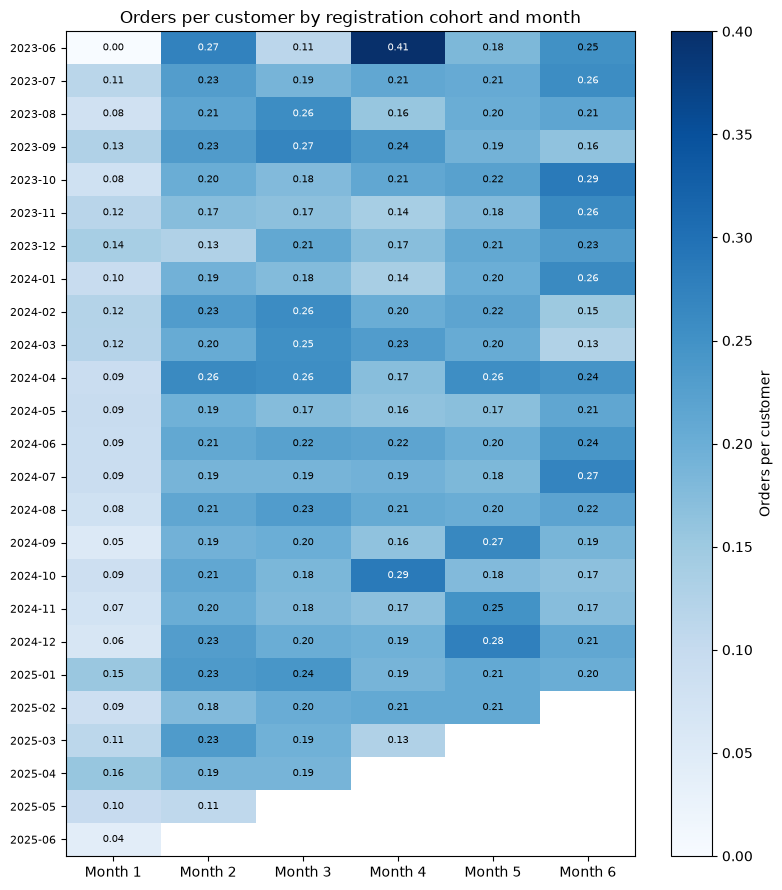

In [17]:
import matplotlib.pyplot as plt

opc = pivot.div(cohort_size, axis=0)
fig, ax = plt.subplots(figsize=(8, 9))
im = ax.imshow(opc.values, cmap="Blues", aspect="auto", vmin=0, vmax=0.4)
ax.set_xticks(range(opc.shape[1])); ax.set_xticklabels([f"Month {k}" for k in opc.columns])
ax.set_yticks(range(opc.shape[0])); ax.set_yticklabels([str(c) for c in opc.index], fontsize=8)
for i in range(opc.shape[0]):
    for j in range(opc.shape[1]):
        v = opc.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if v > 0.25 else "black")
ax.set_title("Orders per customer by registration cohort and month")
fig.colorbar(im, ax=ax, label="Orders per customer")
plt.tight_layout()
plt.savefig("cohort_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

## observation: Cohort analysis

**Method:** customers are grouped by registration month (4,090 customers registered within the data window, 25 cohorts). For each cohort, the table counts orders placed on or after the registration date in Month 1 (the registration month), Month 2, Month 3 and so on; blank cells are months the data does not yet cover.

**Result:** orders per customer are flat at about 0.2 a month from Month 2 onwards (Month 2: 0.20, Month 3: 0.21, Month 6: 0.22), with no sign of the decay that normally shows up as customers drop away. Month 1 is lower (0.10) because it is only a partial month: it counts only the part of the registration month after the registration date.

**Caveat:** this does not show customer retention. 10,255 of the 20,490 orders (50.0%) placed by these customers are dated before their registration date, and 3,108 of the 3,909 customers who ordered have at least one such order, so order dates are unrelated to registration dates in this dataset. Those orders are excluded from the table, and the flat pattern is a consequence of that data issue, not evidence of strong retention. June 2025 is also a partial month (data ends on 23 June), so the last observable month of each cohort is partial.

In [18]:
def status(ok): return "Target met" if ok else "Target missed"
alt_return = returned_status / len(orders) * 100

summary = pd.DataFrame([
    ["GMV", f"₹{gmv/1e7:,.2f} crore", "—", "—"],
    ["Net Revenue (Delivered)", f"₹{net_revenue/1e7:,.2f} crore", "—", "—"],
    ["Average Order Value", f"₹{aov:,.0f}", "—", "—"],
    ["Cancellation Rate", f"{cancel_rate:.2f}%", "< 10%", status(cancel_rate < 10)],
    ["Return Rate (PRD formula)", f"{return_rate:.2f}%", "< 8%", status(return_rate < 8)],
    ["Return Rate (Returned status / all orders)", f"{alt_return:.2f}%", "< 8%", status(alt_return < 8)],
    ["CLV: Premium vs Regular", f"₹{clv.loc['Premium','mean']:,.0f} vs ₹{clv.loc['Regular','mean']:,.0f} ({ratio:.2f}x)", "3x", status(ratio >= 3)],
    ["Month-over-Month Growth", f"{clean.mean():+.2f}% average over {len(clean)} full months", "Trend", "Flat"],
    ["Top Category Revenue Share", f"{cat_share.index[0]} {cat_share.iloc[0]}%", "< 60%", "Within limit" if cat_share.iloc[0] < 60 else "Concentration risk"],
    ["Payment Failure Rate", f"{fail_rate:.2f}%", "< 2%", status(fail_rate < 2)],
    ["Inventory Fill Rate", f"{fill_rate:.1f}%", "> 95%", status(fill_rate > 95)],
], columns=["KPI", "Result", "Target", "Status"])

pd.set_option("display.width", 200, "display.max_colwidth", 80)
print(summary.to_string(index=False))
summary.to_csv("kpi_summary.csv", index=False)

                                       KPI                             Result Target        Status
                                       GMV                      ₹314.74 crore      —             —
                   Net Revenue (Delivered)                      ₹205.39 crore      —             —
                       Average Order Value                            ₹63,198      —             —
                         Cancellation Rate                             11.99%  < 10% Target missed
                 Return Rate (PRD formula)                             30.77%   < 8% Target missed
Return Rate (Returned status / all orders)                              7.87%   < 8%    Target met
                   CLV: Premium vs Regular       ₹532,735 vs ₹361,871 (1.47x)     3x Target missed
                   Month-over-Month Growth +0.51% average over 22 full months  Trend          Flat
                Top Category Revenue Share                  Electronics 57.7%  < 60%  Within limit
          

## Conclusion

 GMV is ₹314.74 crore, of which ₹205.39 crore (65.3%) is net revenue from Delivered orders, at an average order value of ₹63,198. Growth is flat: month-over-month GMV changed by +0.51% on average across the 22 full months, and rose only 5.4% between July 2023 and May 2025.

**Targets.** Of the six KPIs that have a target, five were missed and one is within its limit:
- Cancellation rate is 11.99% (target < 10%), and payment failure rate is 3.50% (target < 2%); the 1,748 failed payments coincide with about 29% of all cancellations.
- Inventory fill rate is 92.2% (target > 95%), driven by 76 Low Stock SKUs rather than fully out-of-stock products (only 2).
- The Premium to Regular CLV ratio is 1.47x (target 3x): Premium customers buy more often but not in larger orders.
- The return rate is 30.77% by the PRD formula, which is inflated by the data (return records on Cancelled and Shipped orders); on a consistent basis it is 7.87%, just inside the 8% target.
- Electronics accounts for 57.7% of revenue, within the 60% limit but only by 2.3 points, so revenue is heavily concentrated.

**Where to focus.** The data points to payment reliability and cancellations (which are linked), restocking of Low Stock SKUs, and reducing dependence on Electronics. These are observations from the data, not tested causes.

**Data caveats.** CLV is based on total_spent, which includes cancelled orders; the category share covers only the orders that have line items (about 80%); and every return record is a full-order refund.

“A cohort analysis was attempted as a bonus, but it cannot show retention because half of the order dates precede the registration dates.”